In [2]:
df = pd.read_csv("vgsales.csv")

In [3]:
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [1]:
import pandas as pd

In [5]:
df.shape

(16598, 11)

## Exploring the Dataset

Before analyzing the data, we first looked at the structure of the dataset, including its columns, data types, and missing values.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [7]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

## Data Cleaning

The dataset contains some missing values in the Year and Publisher columns. We removed rows with missing values in these columns so they would not affect our analysis.

In [8]:
df_clean = df.dropna(subset=["Year", "Publisher"]).copy()
df_clean["Year"] = df_clean["Year"].astype(int)

In [9]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (16598, 11)
Cleaned dataset: (16291, 11)


## Data Analysis and Visualizations

We created several visualizations to explore sales patterns based on genre, platform, publisher, year, and region.

In [10]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


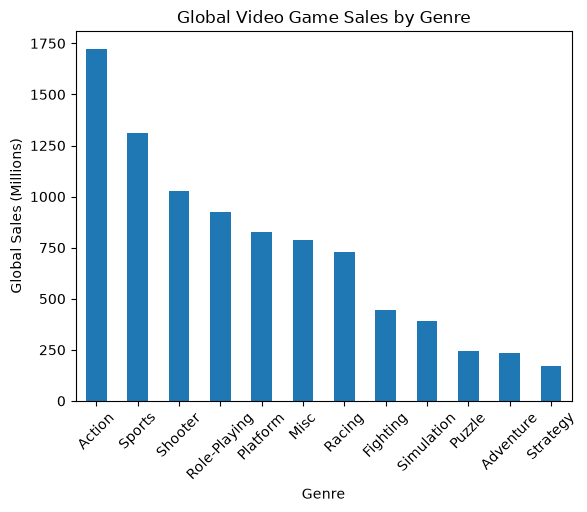

In [11]:
genre_sales = df_clean.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)

genre_sales.plot(kind="bar")

plt.title("Global Video Game Sales by Genre")
plt.xlabel("Genre")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=45)
plt.show()

### Genre Sales

This graph compares total global video game sales across different genres. It helps show which genres have been the most successful based on worldwide sales.

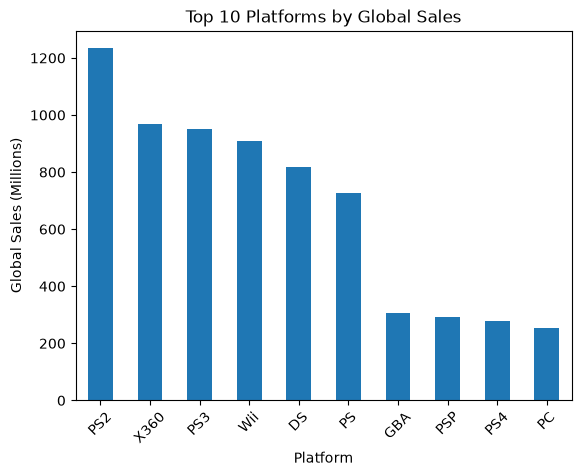

In [12]:
platform_sales = (
    df_clean.groupby("Platform")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

platform_sales.plot(kind="bar")

plt.title("Top 10 Platforms by Global Sales")
plt.xlabel("Platform")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=45)
plt.show()

### Platform Sales

This graph shows the ten platforms with the highest total global video game sales.

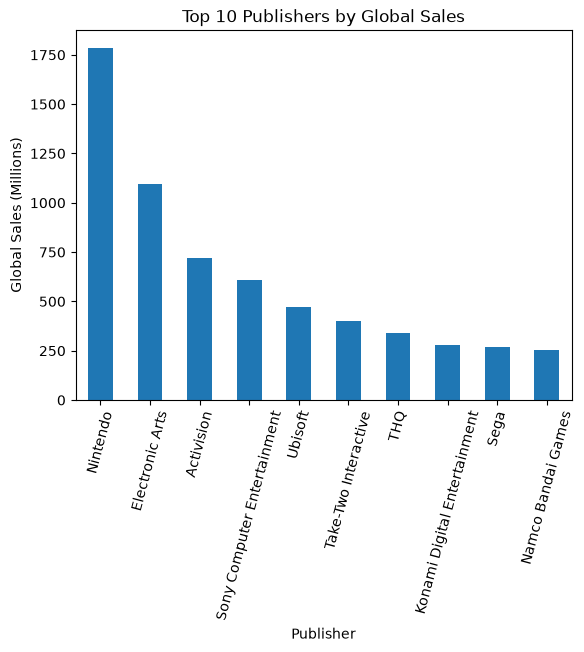

In [13]:
publisher_sales = (
    df_clean.groupby("Publisher")["Global_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

publisher_sales.plot(kind="bar")

plt.title("Top 10 Publishers by Global Sales")
plt.xlabel("Publisher")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=75)
plt.show()

### Publisher Sales

This graph compares the ten publishers with the highest total global video game sales.

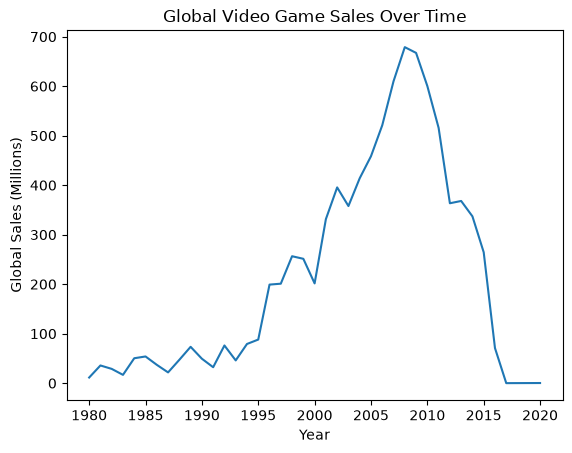

In [15]:
year_sales = df_clean.groupby("Year")["Global_Sales"].sum().sort_index()

year_sales.plot(kind="line")

plt.title("Global Video Game Sales Over Time")
plt.xlabel("Year")
plt.ylabel("Global Sales (Millions)")
plt.show()

### Sales Over Time

This graph shows how global video game sales changed across different release years. It allows us to identify periods when video game sales were especially high or low.

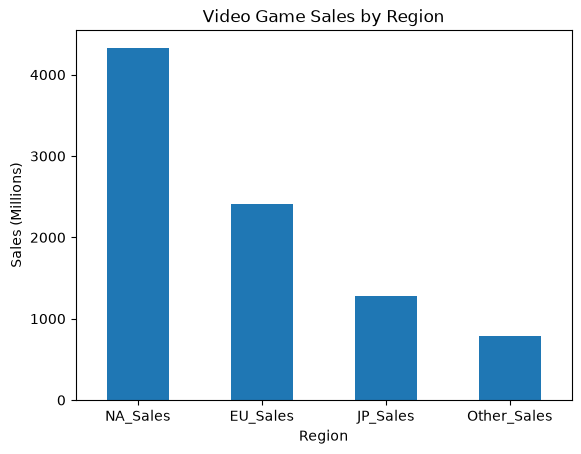

In [16]:
regional_sales = df_clean[
    ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
].sum()

regional_sales.plot(kind="bar")

plt.title("Video Game Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales (Millions)")
plt.xticks(rotation=0)
plt.show()

### Regional Sales

This graph compares total video game sales across North America, Europe, Japan, and other regions.

## Top Selling Video Games

We also looked at the ten games with the highest global sales in the dataset is Wii Sports.

In [17]:
df_clean[
    ["Name", "Platform", "Year", "Genre", "Publisher", "Global_Sales"]
].sort_values("Global_Sales", ascending=False).head(10)

,Name,Platform,Year,Genre,Publisher,Global_Sales
0,Wii Sports,Wii,2006,Sports,Nintendo,82.74
1,Super Mario Bros.,NES,1985,Platform,Nintendo,40.24
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,35.82
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,33.00
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,31.37
5,Tetris,GB,1989,Puzzle,Nintendo,30.26
6,New Super Mario Bros.,DS,2006,Platform,Nintendo,30.01
7,Wii Play,Wii,2006,Misc,Nintendo,29.02
8,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,28.62
9,Duck Hunt,NES,1984,Shooter,Nintendo,28.31
